In [2]:
import os
import pandas as pd
from Bio import SeqIO

# =========================
# PATHS
# =========================

proteome_dir = "../data/proteomes"

fast_dir = "../results/signalp_fast"

slow_dir = "../results/signalp_fast_slow"

# =========================
# FUNCTIONS
# =========================

def count_fasta(fasta_file):

    return sum(1 for _ in SeqIO.parse(fasta_file, "fasta"))


def count_signalp_sp(prediction_file):

    if not os.path.exists(prediction_file):
        return None

    df = pd.read_csv(
        prediction_file,
        sep="\t",
        skiprows=1
    )

    df.columns = [
        "protein_id",
        "Prediction",
        "OTHER",
        "SP",
        "CS_Position"
    ]

    return (df["Prediction"] == "SP").sum()


# =========================
# FIND SPECIES
# =========================

proteome_files = sorted([
    f for f in os.listdir(proteome_dir)
    if f.endswith(".fasta")
])

# =========================
# COLLECT STATS
# =========================

stats = []

for proteome_file in proteome_files:

    species = proteome_file.replace(".fasta", "")

    print(species)

    # -------------------------
    # Proteome size
    # -------------------------

    proteome_path = os.path.join(
        proteome_dir,
        proteome_file
    )

    proteome_count = count_fasta(proteome_path)

    # -------------------------
    # FAST SignalP
    # -------------------------

    fast_prediction = os.path.join(
        fast_dir,
        species,
        "prediction_results.txt"
    )

    fast_sp = count_signalp_sp(fast_prediction)

    # -------------------------
    # SLOW SignalP
    # -------------------------

    slow_prediction = os.path.join(
        slow_dir,
        species,
        "prediction_results.txt"
    )

    slow_sp = count_signalp_sp(slow_prediction)

    # -------------------------
    # Fractions
    # -------------------------

    fast_fraction = (
        fast_sp / proteome_count * 100
        if fast_sp is not None else None
    )

    slow_fraction = (
        slow_sp / proteome_count * 100
        if slow_sp is not None else None
    )

    # relative retention after slow validation
    retention = (
        slow_sp / fast_sp * 100
        if fast_sp and slow_sp is not None else None
    )

    stats.append({
        "species": species,
        "proteins_total": proteome_count,
        "secretome_fast": fast_sp,
        "secretome_slow": slow_sp,
        "fast_%": round(fast_fraction, 2) if fast_fraction else None,
        "slow_%": round(slow_fraction, 2) if slow_fraction else None,
        "slow_retention_%": round(retention, 2) if retention else None
    })

# =========================
# FINAL TABLE
# =========================

stats_df = pd.DataFrame(stats)

stats_df = stats_df.sort_values(
    by="proteins_total",
    ascending=False
)

stats_df

aspergillus_brasiliensis
aspergillus_clavatus
aspergillus_fumigatus
aspergillus_japonicus
aspergillus_nidulans
aspergillus_niger
aspergillus_oryzae
aspergillus_terreus
chaetomium_globosum
chaetomium_thermophilum
fusarium_graminearum
fusarium_oxysporum
myceliophthora_thermophila
neurospora_crassa
penicillium_chrysogenum
penicillium_digitatum
penicillium_oxalicum
penicillium_roqueforti
pleurotus_ostreatus
podospora_anserina
rhizopus_oryzae
talaromyces_amestolkiae
talaromyces_pinophilus
thielavia_terrestris
trichoderma_atroviride
trichoderma_harzianum
trichoderma_reesei
trichoderma_virens
yarrowia_lipolytica


,species,proteins_total,secretome_fast,secretome_slow,fast_%,slow_%,slow_retention_%
20,rhizopus_oryzae,15531,637,612,4.10,3.94,96.08
11,fusarium_oxysporum,14157,1287,1259,9.09,8.89,97.82
10,fusarium_graminearum,14147,1298,1259,9.18,8.90,97.00
5,aspergillus_niger,14069,955,913,6.79,6.49,95.60
25,trichoderma_harzianum,14049,1111,1062,7.91,7.56,95.59
6,aspergillus_oryzae,13597,799,763,5.88,5.61,95.49
0,aspergillus_brasiliensis,12982,1005,961,7.74,7.40,95.62
14,penicillium_chrysogenum,12788,856,831,6.69,6.50,97.08
27,trichoderma_virens,12389,925,892,7.47,7.20,96.43
17,penicillium_roqueforti,12315,704,683,5.72,5.55,97.02


In [3]:
species_map = pd.read_csv(
    "../results/signalp_fast_slow/protein_species_map.csv"
)

species_map["protein"] = (
    species_map["protein"]
    .str.split("|")
    .str[1]
)

deeptmhmm = pd.read_csv(
    "../results/deeptmhmm/deeptmhmm_classification.csv"
)

deeptmhmm_sp = (
    deeptmhmm[
        deeptmhmm["class"] == "SP"
    ]
)

secretome_final = (
    species_map
    .merge(
        deeptmhmm_sp,
        left_on="protein",
        right_on="protein"
    )
    .groupby("species")
    .size()
    .reset_index(name="secretome_final")
)

stats_df = stats_df.merge(
    secretome_final,
    on="species",
    how="left"
)

stats_df["secretome_final"] = (
    stats_df["secretome_final"]
    .fillna(0)
    .astype(int)
)

In [4]:
species_map

,protein,species
0,A0A1L9U2J4,aspergillus_brasiliensis
1,A0A1L9U2T6,aspergillus_brasiliensis
2,A0A1L9U5R7,aspergillus_brasiliensis
3,A0A1L9U6P4,aspergillus_brasiliensis
4,A0A1L9U6P8,aspergillus_brasiliensis
...,...,...
23412,Q6CI94,yarrowia_lipolytica
23413,Q6CIA5,yarrowia_lipolytica
23414,Q6CIA6,yarrowia_lipolytica
23415,W0TYL8,yarrowia_lipolytica


In [5]:
deeptmhmm_sp

,protein,class
0,A0A1L9U2J4,SP
1,A0A1L9U2T6,SP
2,A0A1L9U5R7,SP
3,A0A1L9U6P4,SP
4,A0A1L9U6P8,SP
...,...,...
23410,Q6CI36,SP
23411,Q6CI90,SP
23413,Q6CIA5,SP
23415,W0TYL8,SP


In [6]:
secretome_final

,species,secretome_final
0,aspergillus_brasiliensis,816
1,aspergillus_clavatus,534
2,aspergillus_fumigatus,593
3,aspergillus_japonicus,776
4,aspergillus_nidulans,670
5,aspergillus_niger,765
6,aspergillus_oryzae,684
7,aspergillus_terreus,742
8,chaetomium_globosum,808
9,chaetomium_thermophilum,395


In [7]:
stats_df["final_%"] = (
    stats_df["secretome_final"]
    / stats_df["proteins_total"]
    * 100
).round(2)

stats_df["deeptmhmm_retention_%"] = (
    stats_df["secretome_final"]
    / stats_df["secretome_slow"]
    * 100
).round(2)

In [8]:
stats_df.describe()

,proteins_total,secretome_fast,secretome_slow,fast_%,slow_%,slow_retention_%,secretome_final,final_%,deeptmhmm_retention_%
count,29.000000,29.000000,29.000000,29.000000,29.000000,29.000000,29.000000,29.000000,29.000000
mean,11211.655172,836.965517,807.482759,7.476552,7.213793,96.443448,676.931034,6.025172,83.344138
std,2176.837176,215.382796,209.624089,1.270237,1.247839,0.770896,190.513954,1.131051,2.681675
min,6454.000000,434.000000,418.000000,4.100000,3.940000,95.350000,322.000000,3.200000,77.030000
25%,9942.000000,682.000000,651.000000,6.790000,6.500000,95.620000,535.000000,5.440000,82.030000
50%,10883.000000,809.000000,784.000000,7.470000,7.220000,96.430000,670.000000,5.970000,83.090000
75%,12788.000000,968.000000,923.000000,7.910000,7.560000,97.000000,776.000000,6.400000,84.910000
max,15531.000000,1298.000000,1259.000000,9.870000,9.530000,98.080000,1106.000000,8.180000,89.650000


In [10]:
stats_df.sort_values("species")

,species,proteins_total,secretome_fast,secretome_slow,fast_%,slow_%,slow_retention_%,secretome_final,final_%,deeptmhmm_retention_%
6,aspergillus_brasiliensis,12982,1005,961,7.74,7.40,95.62,816,6.29,84.91
23,aspergillus_clavatus,9140,682,651,7.46,7.12,95.45,534,5.84,82.03
21,aspergillus_fumigatus,9942,751,718,7.55,7.22,95.61,593,5.96,82.59
10,aspergillus_japonicus,12019,968,923,8.05,7.68,95.35,776,6.46,84.07
16,aspergillus_nidulans,10542,818,787,7.76,7.47,96.21,670,6.36,85.13
3,aspergillus_niger,14069,955,913,6.79,6.49,95.60,765,5.44,83.79
5,aspergillus_oryzae,13597,799,763,5.88,5.61,95.49,684,5.03,89.65
19,aspergillus_terreus,10118,903,880,8.92,8.70,97.45,742,7.33,84.32
13,chaetomium_globosum,11038,1009,974,9.14,8.82,96.53,808,7.32,82.96
27,chaetomium_thermophilum,7186,522,512,7.26,7.12,98.08,395,5.50,77.15


In [8]:
stats_df.sort_values("slow_retention_%")

,species,proteins_total,secretome_fast,secretome_slow,fast_%,slow_%,slow_retention_%,secretome_final,final_%,deeptmhmm_retention_%
10,aspergillus_japonicus,12019,968,923,8.05,7.68,95.35,776,6.46,84.07
23,aspergillus_clavatus,9140,682,651,7.46,7.12,95.45,534,5.84,82.03
20,penicillium_oxalicum,9977,660,630,6.62,6.31,95.45,515,5.16,81.75
5,aspergillus_oryzae,13597,799,763,5.88,5.61,95.49,684,5.03,89.65
4,trichoderma_harzianum,14049,1111,1062,7.91,7.56,95.59,899,6.40,84.65
3,aspergillus_niger,14069,955,913,6.79,6.49,95.60,765,5.44,83.79
21,aspergillus_fumigatus,9942,751,718,7.55,7.22,95.61,593,5.96,82.59
6,aspergillus_brasiliensis,12982,1005,961,7.74,7.40,95.62,816,6.29,84.91
25,penicillium_digitatum,9101,493,473,5.42,5.20,95.94,380,4.18,80.34
0,rhizopus_oryzae,15531,637,612,4.10,3.94,96.08,497,3.20,81.21


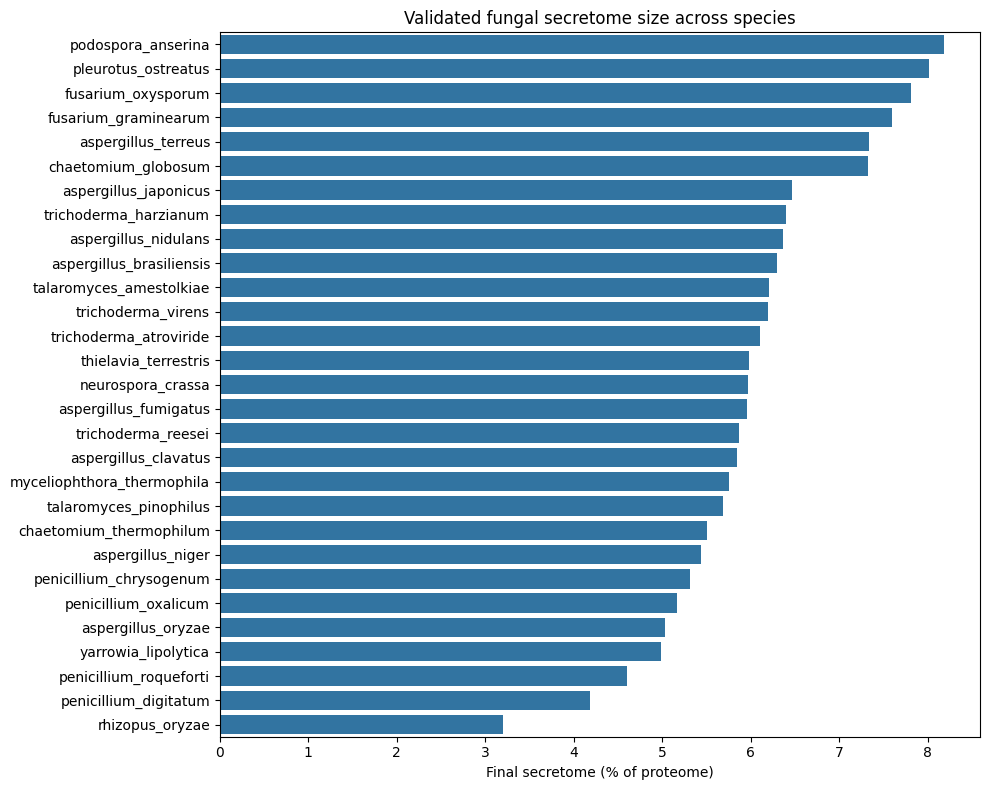

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plot_df = stats_df.sort_values(
    "final_%",
    ascending=False
)

plt.figure(figsize=(10,8))

sns.barplot(
    data=plot_df,
    x="final_%",
    y="species"
)

plt.xlabel("Final secretome (% of proteome)")
plt.ylabel("")
plt.title("Validated fungal secretome size across species")

plt.tight_layout()

plt.savefig(
    "../results/figures/secretome_fraction_across_species.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

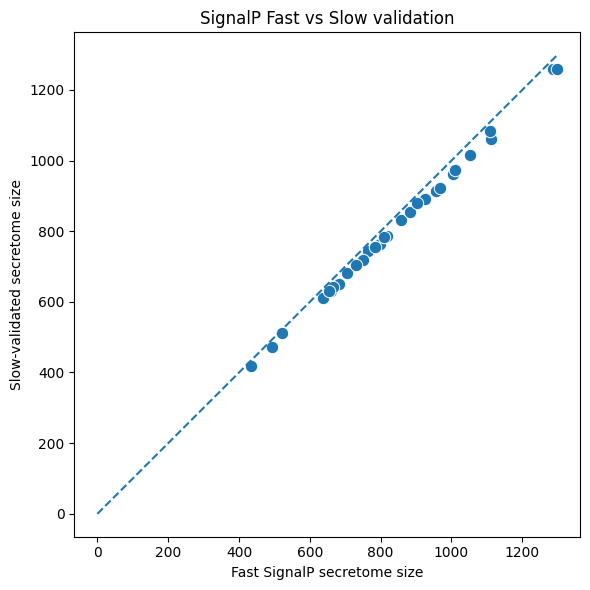

In [11]:
import numpy as np

plt.figure(figsize=(6,6))

sns.scatterplot(
    data=stats_df,
    x="secretome_fast",
    y="secretome_slow",
    s=80
)

max_val = max(
    stats_df["secretome_fast"].max(),
    stats_df["secretome_slow"].max()
)

plt.plot(
    [0, max_val],
    [0, max_val],
    linestyle="--"
)

plt.xlabel("Fast SignalP secretome size")
plt.ylabel("Slow-validated secretome size")

plt.title("SignalP Fast vs Slow validation")

plt.tight_layout()

plt.savefig(
    "../results/figures/fast_vs_slow_signalp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

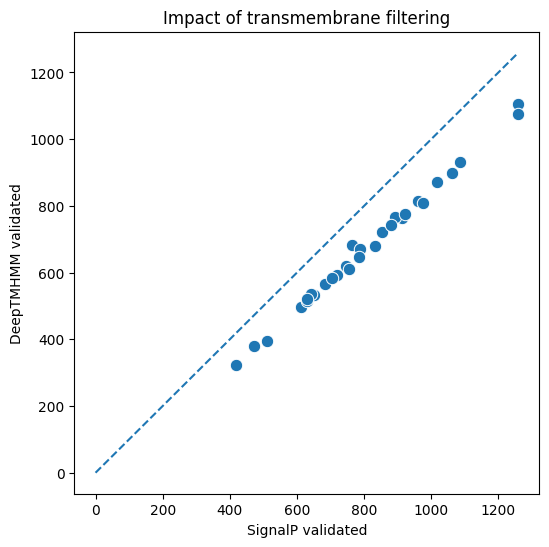

In [12]:
plt.figure(figsize=(6,6))

sns.scatterplot(
    data=stats_df,
    x="secretome_slow",
    y="secretome_final",
    s=80
)

max_val = max(
    stats_df["secretome_slow"].max(),
    stats_df["secretome_final"].max()
)

plt.plot(
    [0, max_val],
    [0, max_val],
    linestyle="--"
)

plt.xlabel("SignalP validated")
plt.ylabel("DeepTMHMM validated")

plt.title(
    "Impact of transmembrane filtering"
)

plt.savefig(
    "../results/figures/signalp_vs_deeptmhmm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

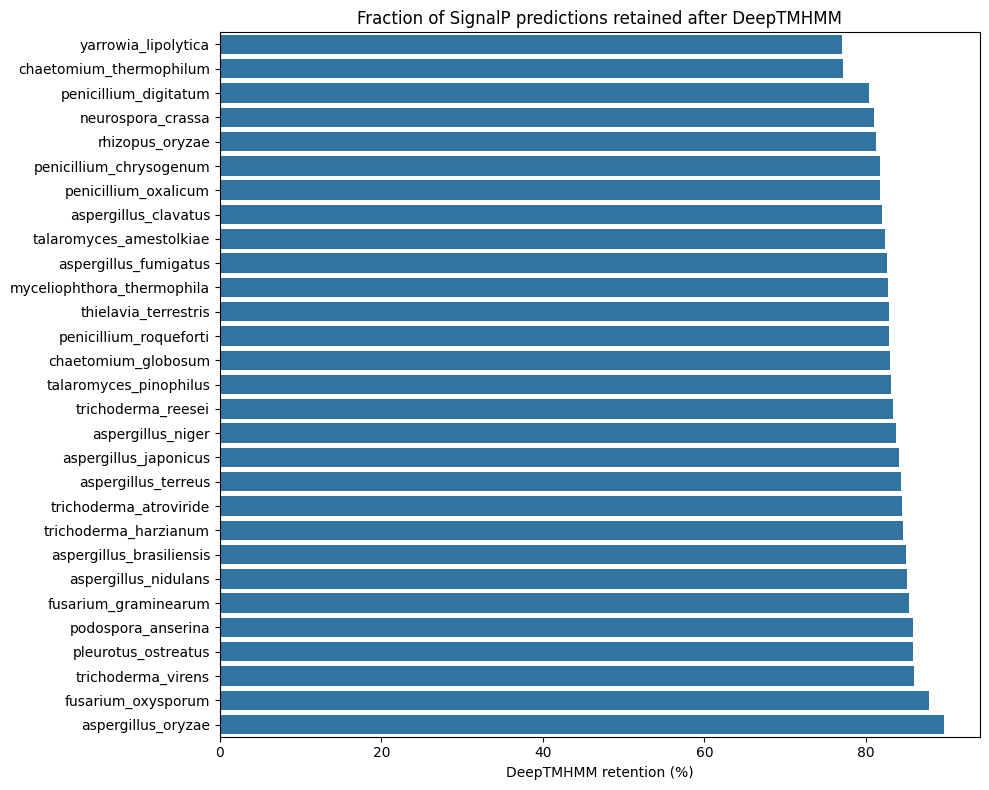

In [13]:
retention_df = stats_df.sort_values(
    "deeptmhmm_retention_%"
)

plt.figure(figsize=(10,8))

sns.barplot(
    data=retention_df,
    x="deeptmhmm_retention_%",
    y="species"
)

plt.xlabel(
    "DeepTMHMM retention (%)"
)

plt.ylabel("")

plt.title(
    "Fraction of SignalP predictions retained after DeepTMHMM"
)

plt.tight_layout()

plt.savefig(
    "../results/figures/deeptmhmm_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
summary = pd.DataFrame({
    "Stage": [
        "SignalP validated",
        "DeepTMHMM validated"
    ],
    "Proteins": [
        stats_df["secretome_slow"].sum(),
        stats_df["secretome_final"].sum()
    ]
})

summary

,Stage,Proteins
0,SignalP validated,23417
1,DeepTMHMM validated,19631
